In [1]:
!pip install trafilatura pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.7/158.7 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.7/254.7 kB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.9/837.9 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 23.2 MB/s eta 0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
  Attempting uninstall: charset_normalizer
    Found existing installation: charset-normalizer 3.4.9
    Uninstalling charset-normalizer-3.4.9:
      Successfully uninstalled charset-normalizer-3.4.9


# Loading the dataset & defining necessary functions

In [2]:
import pandas as pd
import trafilatura
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser
import re

articles = pd.read_csv("sosc314_final_data.csv")
articles = articles.copy()

USER_AGENT = "SOSC314-academic-project/1.0"

# Defining a function that says if the website's robots.txt allows for access
def robots_allows(url):
    parsed = urlparse(url)
    robots_url = f"{parsed.scheme}://{parsed.netloc}/robots.txt"

    parser = RobotFileParser()
    parser.set_url(robots_url)

    try:
        parser.read()
        return parser.can_fetch(USER_AGENT, url)
    except Exception:
        return False
# Defining a function that extracts the articles
def extract_article(url):
    # if not robots_allows(url): ### Decided to ignore what the robots.txt is saying because I have a minimal set of articles in my dataset
    #     return None

    downloaded = trafilatura.fetch_url(url)

    if downloaded is None:
        return None

    return trafilatura.extract(
        downloaded,
        include_comments=False,
        include_tables=False
    )

articles["text"] = articles["url"].apply(extract_article)
articles["word_count"] = articles["text"].fillna("").str.split().str.len()

display(
    articles[["outlet", "title_translated", "word_count"]]
    .rename(columns={
        "outlet": "Outlet",
        "title_translated": "Article title",
        "word_count": "Word count"
    })
    .style
    .hide(axis="index")
    .format({"Word count": "{:,.0f}"}, na_rep="—")
    .set_properties(**{
        "text-align": "left",
        "padding": "8px",
        "white-space": "normal"
    })
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#e8eef4"),
            ("text-align", "left"),
            ("padding", "8px")
        ]}
    ])
)

ERROR:trafilatura.downloads:download error: https://cnbc.mn/news/hcy5 _SafeHTTPSConnectionPool(host='cnbc.mn', port=443): Max retries exceeded with url: /news/hcy5 (Caused by NameResolutionError("_SafeHTTPSConnection(host='cnbc.mn', port=443): Failed to resolve 'cnbc.mn' ([Errno -5] No address associated with hostname)"))
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://urug.mn/158457/
ERROR:trafilatura.downloads:download error: https://cnbc.mn/news/h21w3 _SafeHTTPSConnectionPool(host='cnbc.mn', port=443): Max retries exceeded with url: /news/h21w3 (Caused by NameResolutionError("_SafeHTTPSConnection(host='cnbc.mn', port=443): Failed to resolve 'cnbc.mn' ([Errno -5] No address associated with hostname)"))
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://www.tur.mn/t/s/21200?fbclid=IwY2xjawU4KJdleHRuA2FlbQIxMQBwZG9mBWJyaWQRMW5RVDJFdzZpZ0U4a2JhSFNzcnRjBmFwcF9pZBAyMjIwMzkxNzg4MjAwODkyAAEeAqiZvh64dBQ8_YDas62LAHOkDDhA3Pb4zJoT9yGLPBp2w3jB2h-1-lCK7ww_aem_

Outlet,Article title,Word count
CNBC Mongolia,"Mongolia will build a ""green data center"": What opportunities and challenges are awaiting?",0
Eagle News,"""Green data center"" project will be introduced",101
Ikon News,"Ten memoranda of understanding were signed to advance the development of green, AI-powered data centers.",456
iSee,Prime minister N. Uchral has introduced the initiative of building a green data center in Mongolia,167
Government News,"COP17: MONGOLIA HAS INTRODUCED THE INITIATIVE OF BUILDING A ""GREEN DATA CENTER""",240
Eagle News,An energy data center will be established in Mongolia.,585
State Great Khural News,An AI-based green data center will be established.,563
Urug News,An international AI data center will be established in Tuv Province.,0
iToim News,A national data center for artificial intelligence will be established.,101
Ikon News,"""Utilization and capacity usage of the National Data Center have reached over 90 percent. A Tier IV green data center will be established.""",197


In [3]:
# Defining a function that diagnoses if the article is successfully extracted, downloaded but failed to be extracted, or straight up failed to download

def diagnose_article(url):
    downloaded = trafilatura.fetch_url(url)

    if downloaded is None:
        return pd.Series({
            "download_status": "Download failed",
            "html_length": 0,
            "text": None
        })

    text = trafilatura.extract(
        downloaded,
        include_comments=False,
        include_tables=False
    )

    if not text:
        status = "Downloaded, but extraction failed"
    else:
        status = "Successfully extracted"

    return pd.Series({
        "download_status": status,
        "html_length": len(downloaded),
        "text": text
    })

diagnostic_results = articles["url"].apply(diagnose_article)

articles[
    ["download_status", "html_length", "text"]
] = diagnostic_results

articles["word_count"] = (
    articles["text"]
    .fillna("")
    .str.split()
    .str.len()
)

articles[
    ["title_translated", "download_status", "html_length", "word_count", "url"]
]

ERROR:trafilatura.downloads:download error: https://cnbc.mn/news/hcy5 _SafeHTTPSConnectionPool(host='cnbc.mn', port=443): Max retries exceeded with url: /news/hcy5 (Caused by NameResolutionError("_SafeHTTPSConnection(host='cnbc.mn', port=443): Failed to resolve 'cnbc.mn' ([Errno -5] No address associated with hostname)"))
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://urug.mn/158457/
ERROR:trafilatura.downloads:download error: https://cnbc.mn/news/h21w3 _SafeHTTPSConnectionPool(host='cnbc.mn', port=443): Max retries exceeded with url: /news/h21w3 (Caused by NameResolutionError("_SafeHTTPSConnection(host='cnbc.mn', port=443): Failed to resolve 'cnbc.mn' ([Errno -5] No address associated with hostname)"))
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://mono.mn/n/eronhiy_sayd_nuchral_mong
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://www.tur.mn/t/s/21200?fbclid=IwY2xjawU4KJdleHRuA2FlbQIxMQBwZG9mBWJyaWQRMW5RVDJFdzZpZ0U4a2JhSFNz

,title_translated,download_status,html_length,word_count,url
0,"Mongolia will build a ""green data center"": Wha...",Download failed,0,0,https://cnbc.mn/news/hcy5
1,"""Green data center"" project will be introduced",Successfully extracted,99813,101,https://eagle.mn/r/32iSXr3f8KF
2,Ten memoranda of understanding were signed to ...,Successfully extracted,53369,456,https://ikon.mn/n/3pw3
3,Prime minister N. Uchral has introduced the in...,Successfully extracted,48505,167,https://isee.mn/n/94461
4,COP17: MONGOLIA HAS INTRODUCED THE INITIATIVE ...,Successfully extracted,133608,240,https://www.gov.mn/news/n/8914
...,...,...,...,...,...
59,Mongolia Signs 10 Memoranda of Understanding t...,Successfully extracted,68553,500,https://subeedei.mn/20679/
60,Prime Minister N. Uchral: COP17 should be a co...,Download failed,0,0,https://www.ubfocus.mn/article/eroenhij-sajd-n...
61,T.Dorjkhand: The availability of low-cost rene...,Successfully extracted,113837,103,https://www.24tsag.mn/a/247726
62,T.Dorjkhand: Mongolia has the potential to bec...,Successfully extracted,84818,641,https://gerelnews.mn/s/381


In [4]:
articles["download_status"].value_counts(dropna = False)

,count
download_status,
Successfully extracted,55
Download failed,8
"Downloaded, but extraction failed",1


In [5]:
# Filtering the urls of the failed articles

failed_urls = articles.loc[
    articles["download_status"].isin([
        "Downloaded, but extraction failed",
        "Download failed"
    ]),
    "url"
].tolist()

failed_urls

['https://cnbc.mn/news/hcy5',
 'https://urug.mn/158457/',
 'https://cnbc.mn/news/h21w3',
 'https://mono.mn/n/eronhiy_sayd_nuchral_mong',
 'https://www.uchral.mn/news/MTczNy4yNWE3NGMyY2Y0ZDgwNTc5',
 'https://www.tur.mn/t/s/21200?fbclid=IwY2xjawU4KJdleHRuA2FlbQIxMQBwZG9mBWJyaWQRMW5RVDJFdzZpZ0U4a2JhSFNzcnRjBmFwcF9pZBAyMjIwMzkxNzg4MjAwODkyAAEeAqiZvh64dBQ8_YDas62LAHOkDDhA3Pb4zJoT9yGLPBp2w3jB2h-1-lCK7ww_aem_6e_b1yudm8R6CTsHUyXpzQ',
 'https://meganews.mn/%D1%85%D0%B8%D0%B9%D0%BC%D1%8D%D0%BB-%D0%BE%D1%8E%D1%83%D0%BD%D0%B4-%D1%81%D1%83%D1%83%D1%80%D0%B8%D0%BB%D1%81%D0%B0%D0%BD-%D0%BD%D0%BE%D0%B3%D0%BE%D0%BE%D0%BD-%D0%B4%D0%B0%D1%82%D0%B0-%D1%82%D3%A9/',
 'https://mono.mn/n/chnomingiyn_daraagiyn_mon',
 'https://www.ubfocus.mn/article/eroenhij-sajd-nuchral-cop17-bol-oemnoeh-shijdver-tunhaglalyg-davtah-bus-heregzhiltijg-hurdasgah-baga-hural-bajh-uchirtaj']

In [6]:
# Requesting to get the texts of the failed articles
import requests

def extract_failed_articles(list_of_failed_urls):
    extracted_texts = {}

    headers = {"User-Agent": USER_AGENT}

    # Sending an HTTP request and extracting the text using trafilatura.
    for url in list_of_failed_urls:
        try:
            response = requests.get(
                url,
                headers=headers,
                timeout=20
            )
            response.raise_for_status()

            text = trafilatura.extract(
                response.text,
                include_comments=False,
                include_tables=False
            )

            extracted_texts[url] = text

        except requests.RequestException:
            extracted_texts[url] = None

    return extracted_texts

recovered_texts = extract_failed_articles(failed_urls)

failed_mask = articles["url"].isin(failed_urls)

# Adding the failed articles' text back to the articles dataset

articles.loc[failed_mask, "text"] = (
    articles.loc[failed_mask, "url"]
    .map(recovered_texts)
)

In [7]:
# Adding their word count back

articles["word_count"] = (
    articles["text"]
    .fillna("")
    .str.split()
    .str.len()
)

In [8]:
# Checking if some of the articles still have the word count 0

articles.loc[
    articles["word_count"] == 0,
    ["title_translated", "url", "word_count"]
]

,title_translated,url,word_count
0,"Mongolia will build a ""green data center"": Wha...",https://cnbc.mn/news/hcy5,0
7,An international AI data center will be establ...,https://urug.mn/158457/,0
16,COP17: 10 Memoranda of Understanding Signed on...,https://cnbc.mn/news/h21w3,0
26,Prime Minister N. Uchral presented an initiati...,https://mono.mn/n/eronhiy_sayd_nuchral_mong,0
35,N. Uchral: COP17 should be a conference that a...,https://www.uchral.mn/news/MTczNy4yNWE3NGMyY2Y...,0
41,"An AI-powered, energy-efficient ""Green Data Ce...",https://www.tur.mn/t/s/21200?fbclid=IwY2xjawU4...,0
47,The AI-based “Green Data Center” project will ...,https://meganews.mn/%D1%85%D0%B8%D0%B9%D0%BC%D...,0
50,Concerns surrounding Ch. Nomin’s next money-la...,https://mono.mn/n/chnomingiyn_daraagiyn_mon,0
60,Prime Minister N. Uchral: COP17 should be a co...,https://www.ubfocus.mn/article/eroenhij-sajd-n...,0


In [9]:
for article_id, url in articles.loc[articles["word_count"] == 0, ["article_id", "url"]].itertuples(index=False, name=None):
    print("URL:", url)
    print("Article ID:", article_id)

    print("Robots allowed:", robots_allows(url))

    downloaded = trafilatura.fetch_url(url)
    print("Downloaded:", downloaded is not None)

    if downloaded:
        extracted = trafilatura.extract(downloaded)
        print("Extracted:", extracted is not None)

    print()

ERROR:trafilatura.downloads:download error: https://cnbc.mn/news/hcy5 _SafeHTTPSConnectionPool(host='cnbc.mn', port=443): Max retries exceeded with url: /news/hcy5 (Caused by NameResolutionError("_SafeHTTPSConnection(host='cnbc.mn', port=443): Failed to resolve 'cnbc.mn' ([Errno -5] No address associated with hostname)"))


URL: https://cnbc.mn/news/hcy5
Article ID: A001
Robots allowed: False
Downloaded: False

URL: https://urug.mn/158457/
Article ID: A008
Robots allowed: False


ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://urug.mn/158457/
ERROR:trafilatura.downloads:download error: https://cnbc.mn/news/h21w3 _SafeHTTPSConnectionPool(host='cnbc.mn', port=443): Max retries exceeded with url: /news/h21w3 (Caused by NameResolutionError("_SafeHTTPSConnection(host='cnbc.mn', port=443): Failed to resolve 'cnbc.mn' ([Errno -5] No address associated with hostname)"))
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://mono.mn/n/eronhiy_sayd_nuchral_mong


Downloaded: False

URL: https://cnbc.mn/news/h21w3
Article ID: A017
Robots allowed: False
Downloaded: False

URL: https://mono.mn/n/eronhiy_sayd_nuchral_mong
Article ID: A027
Robots allowed: True
Downloaded: False

URL: https://www.uchral.mn/news/MTczNy4yNWE3NGMyY2Y0ZDgwNTc5
Article ID: A036
Robots allowed: True


ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://www.tur.mn/t/s/21200?fbclid=IwY2xjawU4KJdleHRuA2FlbQIxMQBwZG9mBWJyaWQRMW5RVDJFdzZpZ0U4a2JhSFNzcnRjBmFwcF9pZBAyMjIwMzkxNzg4MjAwODkyAAEeAqiZvh64dBQ8_YDas62LAHOkDDhA3Pb4zJoT9yGLPBp2w3jB2h-1-lCK7ww_aem_6e_b1yudm8R6CTsHUyXpzQ


Downloaded: True
Extracted: False

URL: https://www.tur.mn/t/s/21200?fbclid=IwY2xjawU4KJdleHRuA2FlbQIxMQBwZG9mBWJyaWQRMW5RVDJFdzZpZ0U4a2JhSFNzcnRjBmFwcF9pZBAyMjIwMzkxNzg4MjAwODkyAAEeAqiZvh64dBQ8_YDas62LAHOkDDhA3Pb4zJoT9yGLPBp2w3jB2h-1-lCK7ww_aem_6e_b1yudm8R6CTsHUyXpzQ
Article ID: A042
Robots allowed: False
Downloaded: False

URL: https://meganews.mn/%D1%85%D0%B8%D0%B9%D0%BC%D1%8D%D0%BB-%D0%BE%D1%8E%D1%83%D0%BD%D0%B4-%D1%81%D1%83%D1%83%D1%80%D0%B8%D0%BB%D1%81%D0%B0%D0%BD-%D0%BD%D0%BE%D0%B3%D0%BE%D0%BE%D0%BD-%D0%B4%D0%B0%D1%82%D0%B0-%D1%82%D3%A9/
Article ID: A048


ERROR:trafilatura.downloads:not a 200 response: 404 for URL https://meganews.mn/%D1%85%D0%B8%D0%B9%D0%BC%D1%8D%D0%BB-%D0%BE%D1%8E%D1%83%D0%BD%D0%B4-%D1%81%D1%83%D1%83%D1%80%D0%B8%D0%BB%D1%81%D0%B0%D0%BD-%D0%BD%D0%BE%D0%B3%D0%BE%D0%BE%D0%BD-%D0%B4%D0%B0%D1%82%D0%B0-%D1%82%D3%A9/


Robots allowed: True
Downloaded: False

URL: https://mono.mn/n/chnomingiyn_daraagiyn_mon
Article ID: A051


ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://mono.mn/n/chnomingiyn_daraagiyn_mon
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://www.ubfocus.mn/article/eroenhij-sajd-nuchral-cop17-bol-oemnoeh-shijdver-tunhaglalyg-davtah-bus-heregzhiltijg-hurdasgah-baga-hural-bajh-uchirtaj


Robots allowed: True
Downloaded: False

URL: https://www.ubfocus.mn/article/eroenhij-sajd-nuchral-cop17-bol-oemnoeh-shijdver-tunhaglalyg-davtah-bus-heregzhiltijg-hurdasgah-baga-hural-bajh-uchirtaj
Article ID: A061
Robots allowed: True
Downloaded: False



The articles that still could not be extracted:
- **A001 and A017, cnbc.mn:** Downloads failed because the domain could not be resolved. The robots check also returned False, although this may reflect an inaccessible robots.txt rather than an explicit prohibition.
- **A008, urug.mn, and A042, tur.mn:** The servers rejected the requests with HTTP 403 (Forbidden). The robots checks also returned False.
- **A027 and A051, mono.mn, and A061, ubfocus.mn:** Although the robots checks allowed access, the servers rejected the requests with HTTP 403.
- **A036, uchral.mn:** The webpage downloaded successfully, but trafilatura could not extract article text.

# Preprocessing

In [10]:
# Excluding the articles that were published before May 12th, 2026
# because the news of the initial plan to introduce the green data
# center project was released on the 13th.
articles["date"] = pd.to_datetime(articles["date"])

def date_during_selected_period(date):
    return date > pd.Timestamp("2026-05-12")

articles["during_selected_period"] = articles["date"].apply(
    date_during_selected_period
)

In [11]:
import re
import unicodedata

# Using unicode to normalize all the extracted text to make them lowercase

def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = unicodedata.normalize("NFC", text)
    text = text.lower()
    text = re.sub(r"http\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"\\s+", " ", text)

    return text.strip()

articles["clean_text"] = articles["text"].apply(clean_text)
articles["word_count_clean"] = (
    articles["clean_text"].str.split().str.len())

In [12]:
# Finding articles that are exact duplicates
import hashlib

def hash_nonempty_text(text):
    if pd.isna(text) or not str(text).strip():
        return pd.NA

    return hashlib.sha256(
        str(text).strip().encode("utf-8")
    ).hexdigest()

articles["text_hash"] = articles["clean_text"].apply(hash_nonempty_text)

articles["exact_duplicate"] = (
    articles["text_hash"].notna()
    & articles.duplicated("text_hash", keep=False))

In [13]:
# Finding articles that are missing

def is_missing_article(word_count):
    return word_count == 0

articles["missing_article"] = articles["word_count"].apply(
    is_missing_article
)

In [14]:
# Finding articles that mention Inner Mongolia
def mentions_inner_mongolia(text):
    keywords = [
        "inner mongolia",
        "inner mongolian",
        "өвөр монгол",
        "өвөрмонгол"
    ]

    text = str(text).lower()
    return any(keyword in text for keyword in keywords)

articles["mentions_inner_mongolia"] = articles["text"].apply(
    mentions_inner_mongolia)

In [15]:
# Converting the boolean cells in the flag columns to strings because removing
# them without converting to strings first didn't work

boolean_columns = [
    "mentions_inner_mongolia",
    "during_selected_period",
    "exact_duplicate",
    "missing_article"
]

for column in boolean_columns:
    articles[column] = (
        articles[column]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("true"))

In [16]:
for column in [
    "mentions_inner_mongolia",
    "during_selected_period",
    "exact_duplicate",
    "missing_article"
]:
    print("\n", column)
    print(articles[column].value_counts(dropna=False))


 mentions_inner_mongolia
mentions_inner_mongolia
False    64
Name: count, dtype: int64

 during_selected_period
during_selected_period
True     61
False     3
Name: count, dtype: int64

 exact_duplicate
exact_duplicate
False    56
True      8
Name: count, dtype: int64

 missing_article
missing_article
False    55
True      9
Name: count, dtype: int64


In [17]:
# Creating a flag that removes each duplicate article except for the first one

articles["duplicate_to_remove"] = (
    articles["text_hash"].notna()
    & articles.duplicated("text_hash", keep="first")
)

articles.iloc[[11, 37]][['article_id', 'exact_duplicate', 'duplicate_to_remove']]

,article_id,exact_duplicate,duplicate_to_remove
11,A012,True,False
37,A038,True,True


In [18]:
articles.loc[articles["exact_duplicate"] == True, "article_id"].tolist()

['A012', 'A035', 'A038', 'A041', 'A044', 'A045', 'A046', 'A055']

In [19]:
# Building a remove mask that flags the articles for removal

remove_mask = (
    articles["mentions_inner_mongolia"].eq(True) |
    articles["during_selected_period"].eq(False) |
    articles["duplicate_to_remove"].eq(True) |
    articles["missing_article"].eq(True)
)

print("Articles flagged for removal:", remove_mask.sum())

articles.loc[
    remove_mask,
    [
        "article_id",
        "title",
        "date",
        "mentions_inner_mongolia",
        "during_selected_period",
        "exact_duplicate",
        "word_count",
        "missing_article",
        "outlet"
    ]
]

Articles flagged for removal: 15


,article_id,title,date,mentions_inner_mongolia,during_selected_period,exact_duplicate,word_count,missing_article,outlet
0,A001,Монгол Улс “ногоон дата төв” байгуулна: Ямар б...,2026-08-31,False,True,False,0,True,CNBC Mongolia
7,A008,Төв аймагт хиймэл оюуны олон улсын дата Төв ба...,2026-04-05,False,False,False,0,True,Urug News
8,A009,Хиймэл оюунд зориулсан үндэсний дата төв байгу...,2026-02-10,False,False,False,101,False,iToim News
9,A010,"""Үндэсний дата төвийн ашиглалт, дүүргэлт 90 га...",2026-02-10,False,False,False,197,False,Ikon News
16,A017,"COP17: Ногоон дата төв, сэргээгдэх эрчим хүчни...",2026-08-26,False,True,False,0,True,CNBC Mongolia
26,A027,Ерөнхий сайд Н.Учрал Монгол Улсад ногоон дата ...,2026-08-26,False,True,False,0,True,Mono News
35,A036,"Н.Учрал: COP17 бол өмнөх шийдвэр, тунхаглалыг ...",2026-08-17,False,True,False,0,True,Uchral
37,A038,Монгол Улс “Ногоон хиймэл оюун дата төвийн сан...,2026-09-26,False,True,True,231,False,Barimt.mn
41,A042,"Хиймэл оюунд суурилсан, эрчим хүчний хэмнэлттэ...",2026-05-13,False,True,False,0,True,Tur.mn
44,A045,Ерөнхий сайд Н.Учрал Монгол Улсад ногоон дата ...,2026-08-26,False,True,True,246,False,24Tsag.mn


In [20]:
# Removing the articles

clean_articles = (
    articles.loc[~remove_mask]
    .copy()
    .reset_index(drop=True)
)

print("Original:", len(articles))
print("Removed:", remove_mask.sum())
print("Remaining:", len(clean_articles))

Original: 64
Removed: 15
Remaining: 49


In [21]:
list_of_clean_articles = clean_articles['article_id'].tolist()

print(list_of_clean_articles)

['A002', 'A003', 'A004', 'A005', 'A006', 'A007', 'A011', 'A012', 'A013', 'A014', 'A015', 'A016', 'A018', 'A019', 'A020', 'A021', 'A022', 'A023', 'A024', 'A025', 'A026', 'A028', 'A029', 'A030', 'A031', 'A032', 'A033', 'A034', 'A035', 'A037', 'A039', 'A040', 'A041', 'A043', 'A044', 'A047', 'A049', 'A050', 'A052', 'A053', 'A054', 'A056', 'A057', 'A058', 'A059', 'A060', 'A062', 'A063', 'A064']


# Distribution of the article publication date

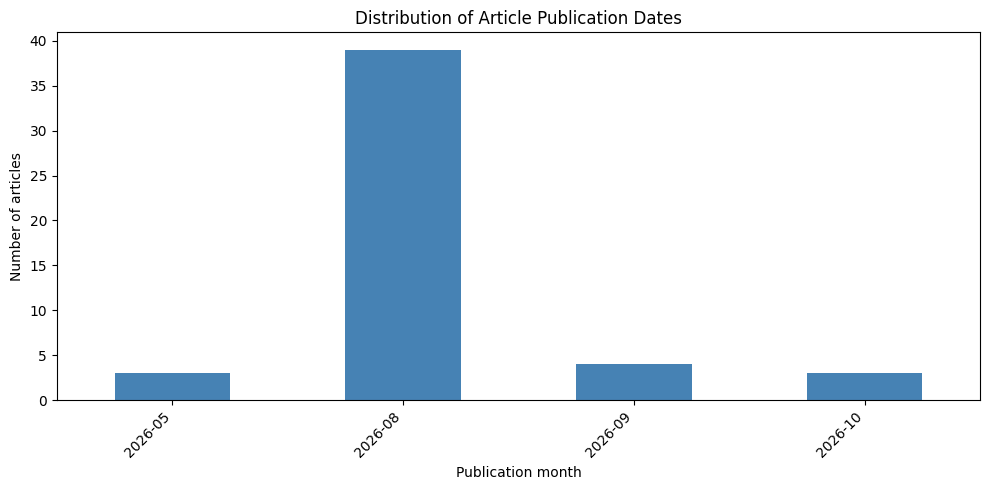

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

dates = pd.to_datetime(clean_articles["date"], errors="coerce")

monthly_counts = (
    dates.dropna()
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

ax = monthly_counts.plot.bar(figsize=(10, 5), color="steelblue")

ax.set_title("Distribution of Article Publication Dates")
ax.set_xlabel("Publication month")
ax.set_ylabel("Number of articles")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Baseline Approach - Human-Coded Frame Assignments

In [24]:
clean_articles["orientation"] = ""
clean_articles["economic_frame"] = 0
clean_articles["technology_frame"] = 0
clean_articles["data_sovereignty_frame"] = 0
clean_articles["environmental_benefit_frame"] = 0
clean_articles["environmental_risk_frame"] = 0
clean_articles["energy_constraint_frame"] = 0
clean_articles["water_constraint_frame"] = 0
clean_articles["governance_frame"] = 0

In [25]:
clean_articles.loc[
    clean_articles["article_id"] == "A002",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [26]:
clean_articles.loc[
    clean_articles["article_id"] == "A003",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [27]:
clean_articles.loc[
    clean_articles["article_id"] == "A004",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [28]:
clean_articles.loc[
    clean_articles["article_id"] == "A005",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1]

In [29]:
clean_articles.loc[
    clean_articles["article_id"] == "A006",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [30]:
clean_articles.loc[
    clean_articles["article_id"] == "A007",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [31]:
clean_articles.loc[
    clean_articles["article_id"] == "A011",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1]

In [32]:
clean_articles.loc[
    clean_articles["article_id"] == "A012",
    ["orientation", "economic_frame", "technology_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [33]:
clean_articles.loc[
    clean_articles["article_id"] == "A013",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame",
     "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame",
     "water_constraint_frame", "governance_frame"]
] = ["Mixed", 1, 1, 1, 1, 1, 1, 1, 1]

In [34]:
clean_articles.loc[
    clean_articles["article_id"] == "A014",
    ["orientation", "economic_frame"]
] = ["Supportive", 1]

In [35]:
clean_articles.loc[
    clean_articles["article_id"] == "A015",
    ["orientation", "economic_frame", "technology_frame",
     "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [36]:
clean_articles.loc[
    clean_articles["article_id"] == "A016",
    ["orientation", "economic_frame", "technology_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [37]:
clean_articles.loc[
    clean_articles["article_id"] == "A018",
    ["orientation", "economic_frame",
     "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [38]:
clean_articles.loc[
    clean_articles["article_id"] == "A019",
    ["orientation", "economic_frame", "governance_frame"]
] = ["Supportive", 1, 1]

In [39]:
clean_articles.loc[
    clean_articles["article_id"] == "A020",
    ["orientation", "economic_frame", "technology_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [40]:
# Creating a list of already analyzed articles and articles yet to be analyzed

list_of_already_analyzed_articles = ['A002', 'A003', 'A004', 'A005', 'A006', 'A007',
                                     'A011', 'A012', 'A013', 'A014', 'A015', 'A016',
                                     'A018', 'A019', 'A020']

articles_yet_to_analyze = [
    article_id
    for article_id in list_of_clean_articles
    if article_id not in list_of_already_analyzed_articles
]

print(articles_yet_to_analyze)

['A021', 'A022', 'A023', 'A024', 'A025', 'A026', 'A028', 'A029', 'A030', 'A031', 'A032', 'A033', 'A034', 'A035', 'A037', 'A039', 'A040', 'A041', 'A043', 'A044', 'A047', 'A049', 'A050', 'A052', 'A053', 'A054', 'A056', 'A057', 'A058', 'A059', 'A060', 'A062', 'A063', 'A064']


In [41]:
articles_to_analyze_dict = (
    articles.loc[
        articles["article_id"].isin(articles_yet_to_analyze),
        ["article_id", "url"]
    ]
    .set_index("article_id")["url"]
    .to_dict()
)

articles_to_analyze_dict

{'A021': 'https://www.icn.mn/news/mongol-ulsad-nogoon-data-tv-bajguulah-edijn-zasgijn-bolomzhijg-olon-ulsad-tanilcuullaa/',
 'A022': 'https://www.khumuun.mn/a/1894',
 'A023': 'https://www.montsame.mn/mn/read/406997',
 'A024': 'https://www.freedom.mn/news/6063',
 'A025': 'https://www.ubim.mn/a/1002',
 'A026': 'https://www.inews.mn/a/54458',
 'A028': 'https://graph.mn/news/5908',
 'A029': 'https://www.reelnews.mn/a/11172/',
 'A030': 'https://rtbn.gov.mn/%d0%bc%d0%be%d0%bd%d0%b3%d0%be%d0%bb-%d1%83%d0%bb%d1%81%d0%b0%d0%b4-%d0%bd%d0%be%d0%b3%d0%be%d0%be%d0%bd-%d0%b4%d0%b0%d1%82%d0%b0-%d1%82%d3%a9%d0%b2-%d0%b1%d0%b0%d0%b9%d0%b3%d1%83%d1%83%d0%bb%d0%b0/',
 'A031': 'https://rtbn.gov.mn/%d0%bc%d0%be%d0%bd%d0%b3%d0%be%d0%bb-%d1%83%d0%bb%d1%81%d0%b0%d0%b4-%d1%85%d1%83%d0%b2%d0%b8%d0%b9%d0%bd-%d1%85%d1%8d%d0%b2%d1%88%d0%bb%d0%b8%d0%b9%d0%bd-%d1%85%d3%a9%d1%80%d3%a9%d0%bd%d0%b3%d3%a9/',
 'A032': 'https://mongoltv.mn/post/179808',
 'A033': 'https://www.polit.mn/a/109825',
 'A034': 'https://www.dobu.

In [42]:
clean_articles.loc[
    clean_articles["article_id"] == "A021",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 0, 1, 0, 1, 0, 1]

In [43]:
clean_articles.loc[
    clean_articles["article_id"] == "A022",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Mixed", 1, 1, 1, 1, 1, 1, 1, 1]

In [44]:
clean_articles.loc[
    clean_articles["article_id"] == "A023",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 0, 0, 0]

In [45]:
clean_articles.loc[
    clean_articles["article_id"] == "A024",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 0, 0, 0]

In [46]:
clean_articles.loc[
    clean_articles["article_id"] == "A025",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 0, 0, 0]

In [47]:
clean_articles.loc[
    clean_articles["article_id"] == "A026",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [48]:
clean_articles.loc[
    clean_articles["article_id"] == "A028",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 0, 0, 1]

In [49]:
clean_articles.loc[
    clean_articles["article_id"] == "A029",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [50]:
clean_articles.loc[
    clean_articles["article_id"] == "A030",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 0, 1, 0, 1, 0, 1]

In [51]:
clean_articles.loc[
    clean_articles["article_id"] == "A031",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 0, 1, 0, 0, 0, 1]

In [52]:
clean_articles.loc[
    clean_articles["article_id"] == "A032",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 0, 0, 0, 0, 1]

In [53]:
clean_articles.loc[
    clean_articles["article_id"] == "A033",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 0, 0, 0, 0, 1]

In [54]:
clean_articles.loc[
    clean_articles["article_id"] == "A034",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [55]:
clean_articles.loc[
    clean_articles["article_id"] == "A035",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 1, 0, 0, 0, 1]

In [56]:
clean_articles.loc[
    clean_articles["article_id"] == "A037",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 0, 0, 0, 0, 1]

In [57]:
clean_articles.loc[
    clean_articles["article_id"] == "A039",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [58]:
clean_articles.loc[
    clean_articles["article_id"] == "A040",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 1, 0, 0, 0, 1]

In [59]:
clean_articles.loc[
    clean_articles["article_id"] == "A041",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [60]:
clean_articles.loc[
    clean_articles["article_id"] == "A043",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [61]:
clean_articles.loc[
    clean_articles["article_id"] == "A044",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [62]:
clean_articles.loc[
    clean_articles["article_id"] == "A047",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [63]:
clean_articles.loc[
    clean_articles["article_id"] == "A048",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [64]:
clean_articles.loc[
    clean_articles["article_id"] == "A049",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [65]:
clean_articles.loc[
    clean_articles["article_id"] == "A050",
    ["orientation", "technology_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [66]:
clean_articles.loc[
    clean_articles["article_id"] == "A052",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [67]:
clean_articles.loc[
    clean_articles["article_id"] == "A053",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [68]:
clean_articles.loc[
    clean_articles["article_id"] == "A054",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [69]:
clean_articles.loc[
    clean_articles["article_id"] == "A056",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [70]:
clean_articles.loc[
    clean_articles["article_id"] == "A057",
    ["orientation", "economic_frame", "governance_frame"]
] = ["Supportive", 1, 1]

In [71]:
clean_articles.loc[
    clean_articles["article_id"] == "A058",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "governance_frame"]
] = ["Mixed", 1, 1, 1, 1]

In [72]:
clean_articles.loc[
    clean_articles["article_id"] == "A059",
    ["orientation", "technology_frame", "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [73]:
clean_articles.loc[
    clean_articles["article_id"] == "A060",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [74]:
clean_articles.loc[
    clean_articles["article_id"] == "A062",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [75]:
clean_articles.loc[
    clean_articles["article_id"] == "A063",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "energy_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1]

In [76]:
clean_articles.loc[
    clean_articles["article_id"] == "A064",
    ["orientation", "economic_frame", "technology_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Mixed", 1, 1, 1, 1, 1, 1, 1]

# Human Frame Assignment Analysis

In [77]:
frame_columns = [
    "economic_frame",
    "technology_frame",
    "data_sovereignty_frame",
    "environmental_benefit_frame",
    "environmental_risk_frame",
    "energy_constraint_frame",
    "water_constraint_frame",
    "governance_frame"
]

In [78]:
frame_counts = clean_articles[frame_columns].sum().sort_values(ascending = False)

frame_percentages = (clean_articles[frame_columns].mean() * 100).sort_values(ascending = False)

frame_summary = pd.DataFrame({"article_count": frame_counts,
                              "percentage": frame_percentages.round(1)})

frame_summary

,article_count,percentage
technology_frame,45,91.8
economic_frame,42,85.7
environmental_benefit_frame,40,81.6
governance_frame,40,81.6
data_sovereignty_frame,22,44.9
energy_constraint_frame,20,40.8
environmental_risk_frame,3,6.1
water_constraint_frame,3,6.1


In [79]:
clean_articles["orientation"].value_counts()

,count
orientation,
Supportive,45
Mixed,4


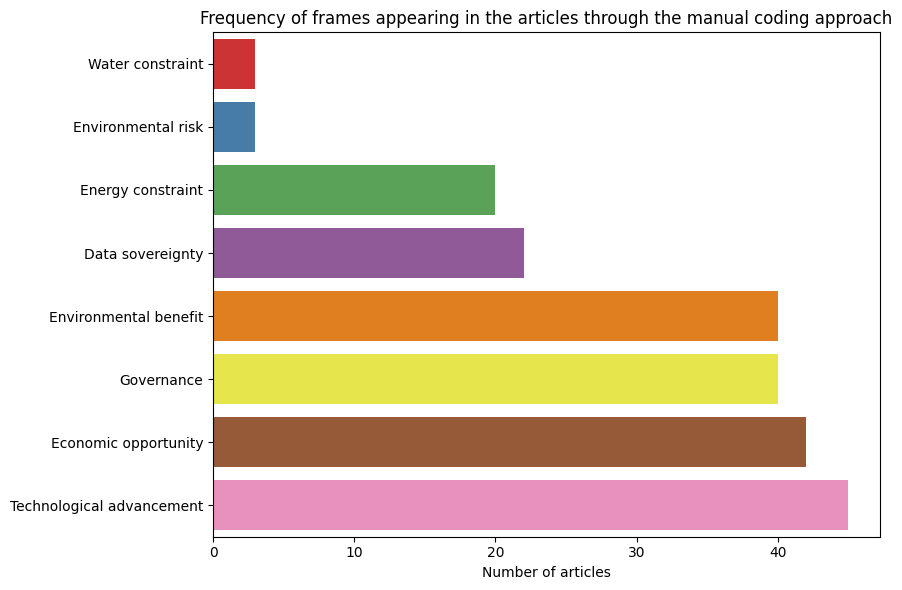

In [80]:
import seaborn as sns

frame_names = {
    "economic_frame": "Economic opportunity",
    "technology_frame": "Technological advancement",
    "data_sovereignty_frame": "Data sovereignty",
    "environmental_benefit_frame": "Environmental benefit",
    "environmental_risk_frame": "Environmental risk",
    "energy_constraint_frame": "Energy constraint",
    "water_constraint_frame": "Water constraint",
    "governance_frame": "Governance"
}

frame_plot = (clean_articles[frame_columns]
              .sum()
              .rename(index = frame_names)
              .sort_values())

plt.figure(figsize=(9, 6))

sns.barplot(
    x=frame_plot.values,
    y=frame_plot.index,
    hue=frame_plot.index,
    palette="Set1",
    legend=False
)

plt.xlabel("Number of articles")
plt.ylabel("")
plt.title("Frequency of frames appearing in the articles through the manual coding approach")
plt.tight_layout()
plt.show()

# Outlet Source Type Analysis

In [124]:
outlet_types = {
    # Government news
    "E-Mongolia News": "Government news",
    "Government News": "Government news",
    "Ministry of Digital Development, Innovation and Communications": "Government news",
    "State Great Khural News": "Government news",

    # Public news
    "MNB News": "Public news",
    "Montsame": "Public news",
    "National Radio and Television Network": "Public news",
}

clean_articles["outlet_type"] = (
    clean_articles["outlet"]
    .str.strip()
    .map(lambda outlet: outlet_types.get(outlet, "Independent news")
         if pd.notna(outlet) else pd.NA)
)

clean_articles["outlet_type"].value_counts()

,count
outlet_type,
Independent news,40
Public news,5
Government news,4


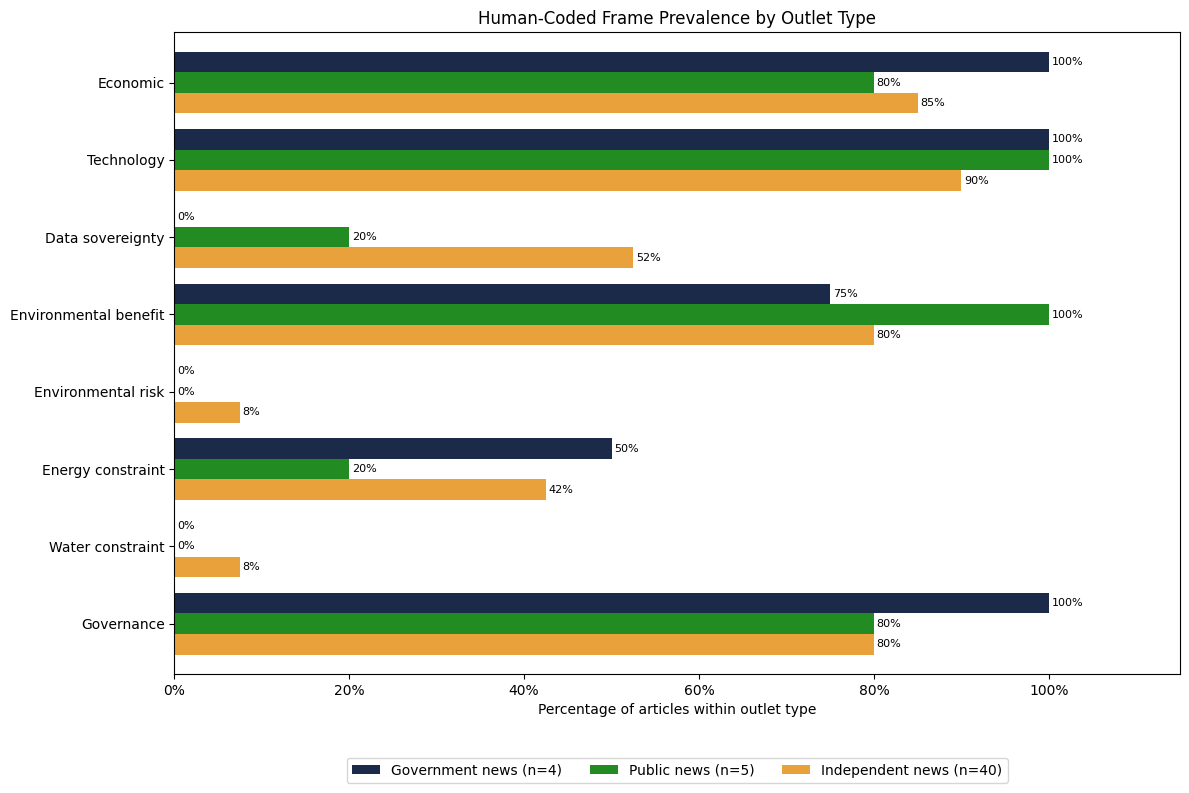

In [128]:
from matplotlib.ticker import PercentFormatter

group_order = [
    "Government news",
    "Public news",
    "Independent news"
]

frame_prevalence = (
    clean_articles.groupby("outlet_type")[frame_columns]
    .mean()
    .reindex(group_order)
    .T
    .mul(100)
)

frame_prevalence.index = [
    frame.removesuffix("_frame").replace("_", " ").capitalize()
    for frame in frame_prevalence.index
]

group_sizes = clean_articles["outlet_type"].value_counts()
frame_prevalence.columns = [
    f"{group} (n={group_sizes.get(group, 0)})"
    for group in group_order
]

ax = frame_prevalence.plot.barh(
    figsize=(12, 8),
    color=["#1B2A49", "#228B22", "#E9A23B"],
    width=0.8
)

ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.set_xticks(range(0, 101, 20))
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.set_xlabel("Percentage of articles within outlet type")
ax.set_ylabel("")
ax.set_title("Human-Coded Frame Prevalence by Outlet Type")
ax.legend(
    title="",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=2, fontsize=8)

plt.tight_layout()
plt.show()

In [130]:
print("Total articles:", len(clean_articles))
print(clean_articles["outlet_type"].value_counts(dropna=False))

Total articles: 49
outlet_type
Independent news    40
Public news          5
Government news      4
Name: count, dtype: int64


# Baseline Dictionary Approach

## Bag-of-Words

In [81]:
from sklearn.feature_extraction.text import CountVectorizer

mongolian_stopwords = {
    "нь", "ын", "ийн", "ыг", "ийг", "д", "т", "аас", "ээс",
    "оос", "өөс", "тай", "тэй", "той", "болон", "ба", "бөгөөд",
    "юм", "байна", "байгаа", "гэсэн", "гэж"
}

vectorizer = CountVectorizer(
    binary=True,
    ngram_range=(1, 1),
    lowercase=True,
    stop_words=list(mongolian_stopwords)
)

matrix = vectorizer.fit_transform(
    clean_articles["clean_text"]
)

bag_of_words_dataframe = pd.DataFrame(
    matrix.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=clean_articles["article_id"]
)

bag_of_words_dataframe

,000,02,03,05,08,09,10,100,11,110,...,өөрчлөлт,өөрчлөлтийг,өөрчлөлтийн,өөрчлөлттэй,өөрчлөлтөд,өөрчлөлтөөр,өөрчлөх,өөрчлөхөөс,өөрөө,өөрөөр
article_id,,,,,,,,,,,,,,,,,,,,,
A002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A003,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A007,0,1,1,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,0
A011,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A012,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A013,0,0,0,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,1,1


In [82]:
bag_of_words_frequency = bag_of_words_dataframe.sum().sort_values(ascending=False)

bag_of_words_frequency.head(20)

,0
монгол,48
дата,47
улсын,47
ногоон,46
эрчим,44
төв,43
хиймэл,43
сайд,42
хөрөнгө,42
хүчний,42


In [83]:
bag_of_words_top_words = bag_of_words_frequency.head(20).index.tolist()
print(bag_of_words_top_words)

['монгол', 'дата', 'улсын', 'ногоон', 'эрчим', 'төв', 'хиймэл', 'сайд', 'хөрөнгө', 'хүчний', 'олон', 'тухай', 'улс', 'засгийн', 'оюун', 'дэд', 'шинэ', 'хүрээнд', 'газрын', 'сэргээгдэх']


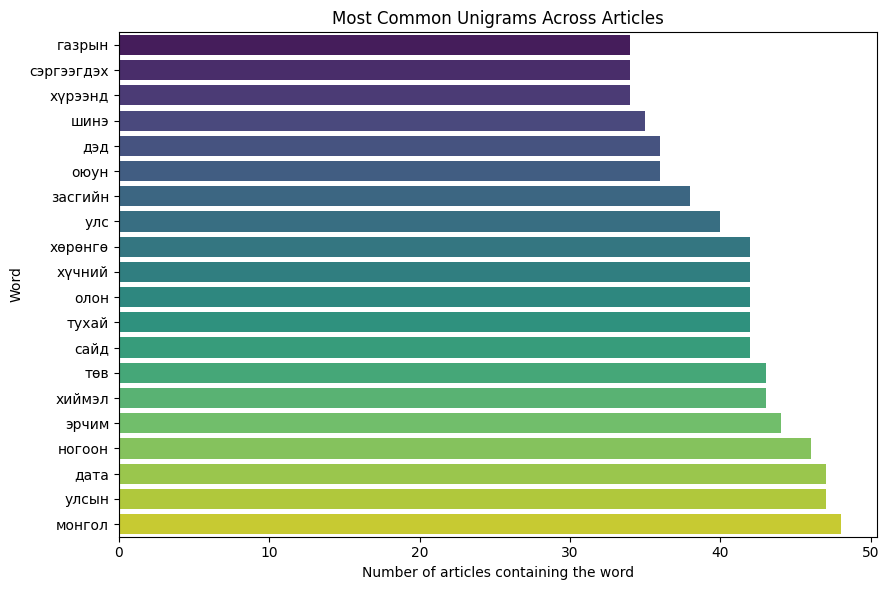

In [84]:
top_words = bag_of_words_frequency.head(20).sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_words.values,
    y=top_words.index,
    hue=top_words.index,
    palette="viridis",
    legend=False
)

plt.xlabel("Number of articles containing the word")
plt.ylabel("Word")
plt.title("Most Common Unigrams Across Articles")
plt.tight_layout()
plt.show()

## Tf-idf

In [85]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    lowercase=True,
    min_df=1,
    stop_words=list(mongolian_stopwords)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    clean_articles["clean_text"]
)

tfidf_dataframe = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=clean_articles["article_id"]
)

tfidf_dataframe

,000,000 барилгын,02,02 үйлдвэрийн,03,03 багцын,03 ны,05,05 13,05 ний,...,өөрөө барьж,өөрөө бүх,өөрөө дата,өөрөө заавал,өөрөө монголын,өөрөө одоо,өөрөө цахим,өөрөө эцсийн,өөрөөр,өөрөөр хэлбэл
article_id,,,,,,,,,,,,,,,,,,,,,
A002,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A003,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A004,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A005,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A006,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A007,0.000000,0.000000,0.028219,0.028219,0.056438,0.028219,0.028219,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A011,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A012,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A013,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.017663,0.000000,0.000000,0.017663,0.023718,0.023718


In [86]:
mean_tfidf = tfidf_dataframe.mean().sort_values(ascending=False)

mean_tfidf.head(20)

,0
эрчим,0.072110
монгол,0.070265
дата,0.069533
улсын,0.052017
ногоон,0.046564
хөрөнгө,0.045929
хиймэл,0.044833
төв,0.043480
хүчний,0.042603
эрчим хүчний,0.042603


In [87]:
tfidf_top_words = mean_tfidf.head(20).index.tolist()
print(tfidf_top_words)

['эрчим', 'монгол', 'дата', 'улсын', 'ногоон', 'хөрөнгө', 'хиймэл', 'төв', 'хүчний', 'эрчим хүчний', 'дэд', 'улс', 'дата төв', 'монгол улс', 'ногоон дата', 'монгол улсын', 'төвийн', 'дата төвийн', 'хүч', 'эрчим хүч']


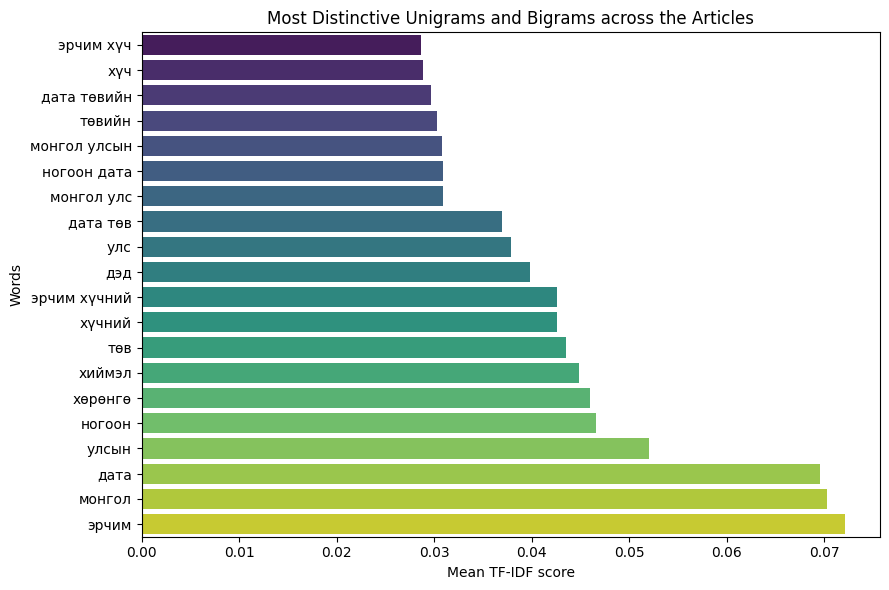

In [88]:
top_tfidf = mean_tfidf.head(20).sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_tfidf.values,
    y=top_tfidf.index,
    hue=top_tfidf.index,
    palette="viridis",
    legend=False
)

plt.xlabel("Mean TF-IDF score")
plt.ylabel("Words")
plt.title("Most Distinctive Unigrams and Bigrams across the Articles")
plt.tight_layout()
plt.show()

### Translated terms

In [89]:
translations = {
    # Past top terms
    "хүчин": "Capacity / power",
    "сэргээгдэх": "Renewable",
    "улс": "Country",
    "технологийн": "Technology / technological",
    "олон": "Many",
    "хүрээнд": "Within the framework",
    "санамж": "Memorandum",
    "монгол улсын": "Mongolia’s",
    "cop17": "COP17",
    "ногоон дата": "Green data",
    "дэд": "Infrastructure / sub-",
    "дата төв": "Data center",
    "хөрөнгө": "Investment / capital",
    "хиймэл": "Artificial",
    "ногоон": "Green",
    "төв": "Center",
    "улсын": "Country’s",
    "монгол": "Mongolia",
    "эрчим": "Energy",
    "дата": "Data",
    "оюуны": "Intelligence",
    "талуудын": "Parties’",
    "хамтын": "Cooperative / joint",
    "оруулалт": "Investment / contribution",
    "тухай": "About",
    "хөгжлийн": "Development",
    "сайд": "Minister",
    "хүчний": "Power / energy (possessive)",
    "эрчим хүчний": "Energy / electricity (possessive)",
    "эрчим хүч": "Energy / electricity",
    "монгол улс": "Mongolia",
    "төвийн": "Center’s / of the center",
    "дата төвийн": "Data center’s / of the data center",
    "оюун": "Intelligence / mind",
    "шинэ": "New",
    "төсөл": "Project",
    "засгийн": "Government’s",

    # Additional terms from the expanded dataset
    "газрын": "Land’s / of the land",
    "байгуулах": "Establish / build",
    "бага": "Small / minor (conference in 'бага хурал')",
}

In [90]:
def translate_label(term):
    english = translations.get(term, term)
    return f"{term} — {english}"

### Top Terms Found by BoW and TF-IDF Representations

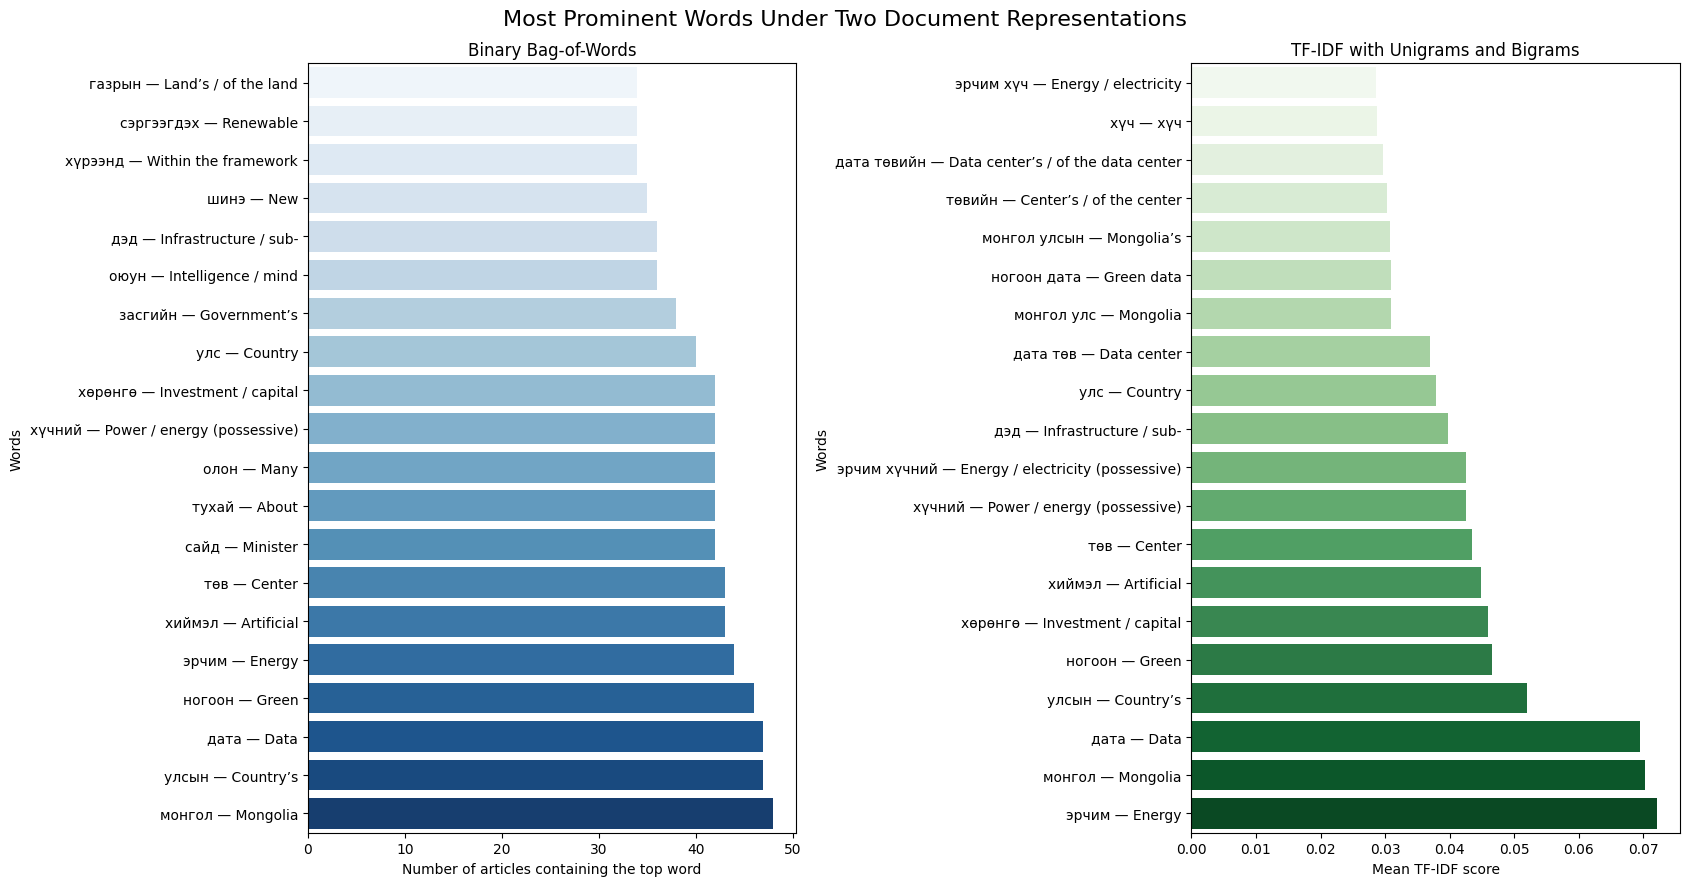

In [91]:
top_bag_of_words = bag_of_words_frequency.head(20).sort_values()
top_tfidf = mean_tfidf.head(20).sort_values()

top_bag_of_words.index = [translate_label(term) for term in top_bag_of_words.index]
top_tfidf.index = [translate_label(term) for term in top_tfidf.index]

fig, axes = plt.subplots(1, 2, figsize=(17, 9))

# Bag-of-words
sns.barplot(
    x=top_bag_of_words.values,
    y=top_bag_of_words.index,
    hue=top_bag_of_words.index,
    palette="Blues",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Binary Bag-of-Words")
axes[0].set_xlabel("Number of articles containing the top word")
axes[0].set_ylabel("Words")

# TF-IDF
sns.barplot(
    x=top_tfidf.values,
    y=top_tfidf.index,
    hue=top_tfidf.index,
    palette="Greens",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("TF-IDF with Unigrams and Bigrams")
axes[1].set_xlabel("Mean TF-IDF score")
axes[1].set_ylabel("Words")

fig.suptitle(
    "Most Prominent Words Under Two Document Representations",
    fontsize=16)

plt.tight_layout()
plt.savefig(
    "bow_tfidf_comparison.png",
    dpi=300,
    bbox_inches="tight")
plt.show()

Creating frame dictionaries using stems and phrases from the top words found from the Bag-of-Words and Tf-idf

*   \w* permits different endings.
*   \s+ permits one or more spaces between words.

In [92]:
frame_dictionary = {
    "economic_proxy": [
        r"хөрөнгө\s+оруулалт\w*",
        r"хөрөнгө\s+оруулагч\w*",
        r"эдийн\s+зас\w*",
        r"санхүүжилт\w*",
        r"орлого\s+олох",
        r"экспорт\w*",
        r"хөрөнгө\s+оруулах\w*",
        r"хөрөнгө\s+татах\w*",
        r"эдийн\s+засгийн\s+шинэ\s+боломж\w*",
        r"шинэ\s+эдийн\s+зас\w*",
    ],

    "technology_proxy": [
        r"хиймэл\s+оюун\w*",
        r"технолог\w*",
        r"дэд\s+бүтэц",
        r"өндөр\s+хүчин\s+чадал\w*",
        r"өгөгдөл\s+хадгал\w*",
        r"тооцоол\w*",
        r"дижитал\s+шилжилт\w*",
        r"дата\s+төв\w*",
        r"дэд\s+бүтц\w*",
    ],

    "data_sovereignty_proxy": [
        r"дижитал\s+бие\s+даасан\s+байдал",
        r"өгөгдлийн\s+тусгаар\s+тогтнол",
        r"өгөгдл\w*\s+дотооддоо\s+хадгал\w*",
        r"өгөгдл\w*\s+монгол\w*\s+хадгал\w*",
        r"өгөгдл\w*\s+хамгаал\w*",
        r"sovereign\s+by\s+design",
    ],

    "environmental_benefit_proxy": [
        r"сэргээгдэх\s+эрчим\s+хүч\w*",
        r"эрчим\s+хүчний\s+хэмнэлт\w*",
        r"эрчим\s+хүчний\s+үр\s+ашиг\w*",
        r"цэвэр\s+эрчим\s+хүч\w*",
        r"нүүрстөрөгчийн\s+ялгар\w*\s+бууруул\w*",
        r"илүүдэл\s+дулаан\w*\s+дахин\s+ашигла\w*",
        r"ногоон\s+эрчим\s+хүч\w*",
        r"ногоон\s+шилжилт\w*",
        r"эрчим\s+хүч\w*\s+хэмнэ\w*",
    ],

    "environmental_risk_proxy": [
        r"байгаль\s+орчны\s+сөрөг\s+нөлөө",
        r"нүүрстөрөгчийн\s+ялгар\w*",
        r"агаарын\s+бохирдол",
        r"нүүрсээр\s+үйлдвэрлэсэн\s+цахилгаан",
        r"экологийн\s+эрсдэл",
    ],

    "energy_constraint_proxy": [
        r"эрчим\s+хүчний\s+дутагдал",
        r"эрчим\s+хүчний\s+хомсдол",
        r"цахилгаан\s+хангамжийн\s+найдвартай\s+байдал",
        r"эрчим\s+хүчээр\s+хангах\s+боломжгүй",
        r"шинэ\s+эрчим\s+хүчний\s+эх\s+үүсвэр",
        r"тусгай\s+зориулалтын\s+эрчим\s+хүчний\s+дэд\s+бүтэц",
        r"эрчим\s+хүчний\s+найдвартай\s+байдал",
        r"эрчим\s+хүчний\s+тогтвортой\s+байдал",
        r"эрчим\s+хүчний\s+хэрэгцээ",
        r"эрчим\s+хүчний\s+эрэлт",
    ],

    "water_constraint_proxy": [
        r"усны\s+хомсдол",
        r"усны\s+хэрэглээ",
        r"хөргөлтийн\s+ус",
        r"бага\s+ус\s+хэрэглэдэг\s+хөргөлт",
    ],

    "governance_proxy": [
        r"санамж\s+бичиг\w*",
        r"хамтын\s+ажиллагаа",
        r"засгийн\s+газ\w*",
        r"өгөгдлийн\s+тухай\s+хууль\w*",
        r"хууль\s+эрх\s+зүйн\s+орчин\w*",
        r"бодлогын\s+арга\s+хэмжээ\w*",
        r"газар\s+ашиглалтын\s+бодлог\w*",
        r"газрын\s+зөвшөөрөл\w*",
    ]
}

## Pattern Matching

In [93]:
# Creating a function that finds any of the patterns in the frame dictionary

def contains_any_pattern(text, patterns):
    text = str(text).lower()

    return int(any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in patterns
    ))

for frame, patterns in frame_dictionary.items():
    clean_articles[frame] = clean_articles["clean_text"].apply(
        lambda text: contains_any_pattern(text, patterns)
    )

In [94]:
# Adding the proxy columns to the clean_articles sheet

proxy_columns = list(frame_dictionary.keys())

clean_articles[
    ["article_id"] + proxy_columns
]

,article_id,economic_proxy,technology_proxy,data_sovereignty_proxy,environmental_benefit_proxy,environmental_risk_proxy,energy_constraint_proxy,water_constraint_proxy,governance_proxy
0,A002,0,1,0,1,0,0,0,0
1,A003,1,1,1,1,0,0,0,1
2,A004,1,1,0,1,0,0,0,1
3,A005,1,1,0,1,0,0,0,1
4,A006,1,1,0,1,0,0,0,1
5,A007,1,1,0,1,0,0,0,1
6,A011,1,1,0,1,0,0,0,1
7,A012,1,1,0,1,0,0,0,1
8,A013,1,1,1,1,0,0,1,1
9,A014,1,1,0,0,0,0,0,0


In [95]:
# Counting how many articles has the frames that were built from
# the dictionary proxy and estimating their percentage
proxy_frame_summary = pd.DataFrame({
    "article_count": clean_articles[proxy_columns].sum(),
    "percentage": clean_articles[proxy_columns].mean().mul(100).round(1)
})

proxy_frame_summary

,article_count,percentage
economic_proxy,47,95.9
technology_proxy,49,100.0
data_sovereignty_proxy,14,28.6
environmental_benefit_proxy,44,89.8
environmental_risk_proxy,5,10.2
energy_constraint_proxy,6,12.2
water_constraint_proxy,6,12.2
governance_proxy,35,71.4


In [98]:
# Comparing the frame findings from human-coded assignment and dictionary-based frame proxy

comparison_columns = [
    column
    for frame in frame_columns
    for column in [frame, f"{frame.removesuffix('_frame')}_proxy"]
]

comparison = clean_articles[comparison_columns]

comparison.head()

,economic_frame,economic_proxy,technology_frame,technology_proxy,data_sovereignty_frame,data_sovereignty_proxy,environmental_benefit_frame,environmental_benefit_proxy,environmental_risk_frame,environmental_risk_proxy,energy_constraint_frame,energy_constraint_proxy,water_constraint_frame,water_constraint_proxy,governance_frame,governance_proxy
0,1,0,1,1,1,0,1,1,0,0,0,0,0,0,0,0
1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,1,1
2,1,1,1,1,0,0,1,1,0,0,0,0,0,0,1,1
3,1,1,1,1,0,0,1,1,0,0,1,0,0,0,1,1
4,1,1,1,1,1,0,1,1,0,0,1,0,0,0,1,1


In [99]:
# Comparing the frequency of frames appearing in the articles based on both presentations

count_comparison = pd.DataFrame(
    {
        "Human-coded": [
            clean_articles[frame].sum()
            for frame in frame_columns
        ],
        "Top-term proxies": [
            clean_articles[f"{frame.removesuffix('_frame')}_proxy"].sum()
            for frame in frame_columns
        ],
    },
    index=frame_columns,
)

count_comparison

,Human-coded,Top-term proxies
economic_frame,42,47
technology_frame,45,49
data_sovereignty_frame,22,14
environmental_benefit_frame,40,44
environmental_risk_frame,3,5
energy_constraint_frame,20,6
water_constraint_frame,3,6
governance_frame,40,35


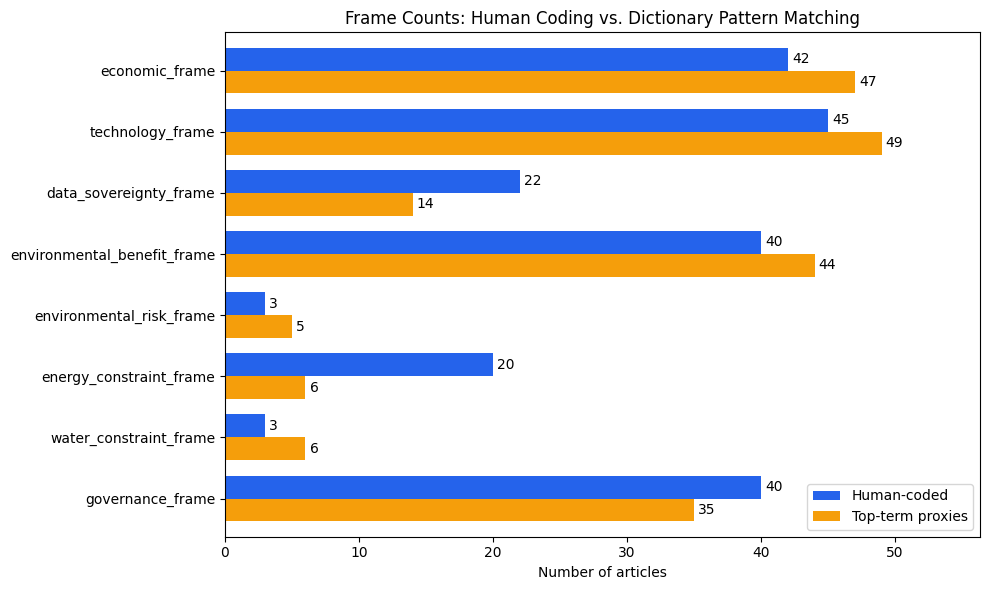

In [100]:
ax = count_comparison.plot.barh(
    figsize=(10, 6),
    color=["#2563EB", "#F59E0B"],
    width=0.75
)

ax.invert_yaxis()
ax.set_title("Frame Counts: Human Coding vs. Dictionary Pattern Matching")
ax.set_xlabel("Number of articles")
ax.set_ylabel("")
ax.legend(title="")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

ax.margins(x=0.15)
plt.tight_layout()
plt.show()

# Preprocessing Sensitivity

Inspecting how the TF-IDF representation technique is sensitive without the use of stopwords or the n-grams being different

In [101]:
def get_top_tfidf(texts, stopwords=None, ngram_range=(1, 1), n=20):
    vectorizer = TfidfVectorizer(
        stop_words=stopwords,
        ngram_range=ngram_range
    )

    matrix = vectorizer.fit_transform(texts)
    scores = matrix.mean(axis=0).A1
    terms = vectorizer.get_feature_names_out()

    return list(
        terms[scores.argsort()[::-1][:n]]
    )

# Original Version: Stopwords, n-gram range being 1:2
top_tfidf_original = get_top_tfidf(
    clean_articles["clean_text"],
    stopwords=list(mongolian_stopwords),
    ngram_range=(1, 2)
)

# No Stopwords Version: No stopwords, n-gram range being 1:1
top_tfidf_no_stopwords = get_top_tfidf(
    clean_articles["clean_text"],
    stopwords=None,
    ngram_range=(1, 1)
)

# Unigram Version: Stopwords, n-gram range being 1:1
top_tfidf_unigram = get_top_tfidf(
    clean_articles["clean_text"],
    stopwords=list(mongolian_stopwords),
    ngram_range=(1, 1)
)

Inspecting how the Bag-of-Words representation technique is sensitive without the use of stopwords or the n-grams being different

In [102]:
def get_top_bow(texts, stopwords=None, ngram_range=(1, 1), n=20):
    vectorizer = CountVectorizer(
        binary = True,
        stop_words=list(stopwords) if stopwords is not None else None,
        ngram_range=ngram_range
    )

    matrix = vectorizer.fit_transform(texts)
    scores = matrix.mean(axis=0).A1
    terms = vectorizer.get_feature_names_out()

    return list(
        terms[scores.argsort()[::-1][:n]]
    )

# Original Version: Mongolian stopwords, n-gram range being 1:1
top_bow_original = get_top_bow(
    clean_articles["clean_text"],
    stopwords=mongolian_stopwords,
    ngram_range=(1, 1)
)

# No Stopwords Version: No stopwords, n-gram range being 1:1
top_bow_no_stopwords = get_top_bow(
    clean_articles["clean_text"],
    stopwords=None,
    ngram_range=(1, 1)
)

# Bigram Version: Mongolian stopwords, n-gram range being 1:2
top_bow_bigrams = get_top_bow(
    clean_articles["clean_text"],
    stopwords=mongolian_stopwords,
    ngram_range=(1, 2)
)

Estimating the Jaccard similarity coefficient
$$
J(A,B) = \frac{|A \cap B|}{|A \cup B|}
$$

0 = no shared terms

1 = exactly the same terms

0.5 = moderate overlap

In [103]:
def jaccard(list1, list2):
    set1, set2 = set(list1), set(list2)
    return len(set1 & set2) / len(set1 | set2)

# Comparing TF-IDF results across preprocessing choices
print("Original vs No stopwords:", jaccard(top_tfidf_original, top_tfidf_no_stopwords))
print("Original vs Unigram:", jaccard(top_tfidf_original, top_tfidf_unigram))
print("No stopwords vs Unigram:", jaccard(top_tfidf_no_stopwords, top_tfidf_unigram))

Original vs No stopwords: 0.48148148148148145
Original vs Unigram: 0.48148148148148145
No stopwords vs Unigram: 0.7391304347826086


In [104]:
# Comparing Bag-of-Words results across preprocessing choices
print("Original vs No stopwords:", jaccard(top_bow_original, top_bow_no_stopwords))
print("Original vs Bigram:", jaccard(top_bow_original, top_bow_bigrams))
print("No stopwords vs Bigram:", jaccard(top_bow_no_stopwords, top_bow_bigrams))

Original vs No stopwords: 0.6
Original vs Bigram: 0.5384615384615384
No stopwords vs Bigram: 0.5384615384615384


### Agreement between human-coded framing and dictionary-based proxies

In [105]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparisons = {
    "Economic": ("economic_frame", "economic_proxy"),
    "Technology": ("technology_frame", "technology_proxy"),
    "Data Sovereignty Frame": ("data_sovereignty_frame", "data_sovereignty_proxy"),
    "Environmental benefit": (
        "environmental_benefit_frame",
        "environmental_benefit_proxy"
    ),
    "Environmental risk": (
        "environmental_risk_frame",
        "environmental_risk_proxy"
    ),
    "Energy constraint": (
        "energy_constraint_frame",
        "energy_constraint_proxy"
    ),
    "Water constraint": (
        "water_constraint_frame",
        "water_constraint_proxy"
    ),
    "Governance": ("governance_frame", "governance_proxy")
}

results = []

for frame, (manual, proxy) in comparisons.items():
    results.append({
        "frame": frame,
        "precision": precision_score(
            clean_articles[manual],
            clean_articles[proxy],
            zero_division=0
        ),
        "recall": recall_score(
            clean_articles[manual],
            clean_articles[proxy],
            zero_division=0
        ),
        "f1": f1_score(
            clean_articles[manual],
            clean_articles[proxy],
            zero_division=0
        )
    })

diagnostic_results = pd.DataFrame(results)
diagnostic_results

,frame,precision,recall,f1
0,Economic,0.872340,0.976190,0.921348
1,Technology,0.918367,1.000000,0.957447
2,Data Sovereignty Frame,1.000000,0.636364,0.777778
3,Environmental benefit,0.909091,1.000000,0.952381
4,Environmental risk,0.200000,0.333333,0.250000
5,Energy constraint,1.000000,0.300000,0.461538
6,Water constraint,0.500000,1.000000,0.666667
7,Governance,1.000000,0.875000,0.933333


**Precision:** When the dictionary detects a frame, how often does manual coding agree?

**Recall:** How many manually identified frames does the dictionary capture?

**F1:** A summary of precision and recall.

### Visualization of the Comparison between Human-Coded and Dictionary-Based Frame Finding Techniques

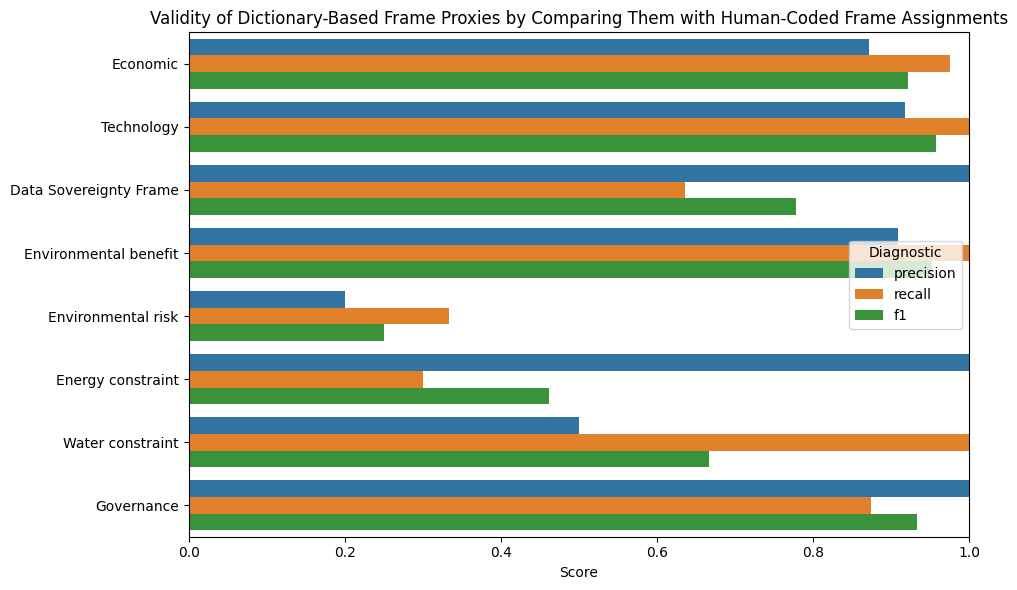

In [106]:
plot_data = diagnostic_results.melt(
    id_vars="frame",
    var_name="Diagnostic",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="Score",
    y="frame",
    hue="Diagnostic"
)

plt.xlim(0, 1)
plt.xlabel("Score")
plt.ylabel("")
plt.title("Validity of Dictionary-Based Frame Proxies by Comparing Them with Human-Coded Frame Assignments")
plt.tight_layout()

plt.savefig(
    "validity_of_dictionary_based_proxies.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Modeling

In [108]:
frame_columns = [
    "economic_frame",
    "technology_frame",
    "data_sovereignty_frame",
    "environmental_benefit_frame",
    "environmental_risk_frame",
    "energy_constraint_frame",
    "water_constraint_frame",
    "governance_frame",
]

proxy_columns = [
    f"{frame.removesuffix('_frame')}_proxy"
    for frame in frame_columns
]

assert clean_articles[frame_columns].notna().all().all()
assert clean_articles[frame_columns].isin([0, 1]).all().all()

model_df = clean_articles.reset_index(drop=True).copy()

X = model_df["clean_text"].fillna("")
y = model_df[frame_columns].astype(int).to_numpy()

assert X.str.strip().ne("").all(), "Remove or resolve empty texts first."

stopwords = sorted(mongolian_stopwords)

# Inspecting the number of positive and negative articles that are available per frame.
label_counts = pd.DataFrame({
    "Positive articles": y.sum(axis=0),
    "Negative articles": (1 - y).sum(axis=0),
}, index=frame_columns)

label_counts

,Positive articles,Negative articles
economic_frame,42,7
technology_frame,45,4
data_sovereignty_frame,22,27
environmental_benefit_frame,40,9
environmental_risk_frame,3,46
energy_constraint_frame,20,29
water_constraint_frame,3,46
governance_frame,40,9


In [109]:
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support

## BoW+LR
## TF-IDF+LR

In [110]:
models = {
    "Binary BoW + LR": Pipeline([
        ("vectorizer", CountVectorizer(
            binary=True,
            stop_words=stopwords,
            ngram_range=(1, 1),
            min_df=1
        )),
        ("classifier", OneVsRestClassifier(
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                random_state=123
            )
        ))
    ]),

    "TF-IDF + LR": Pipeline([
        ("vectorizer", TfidfVectorizer(
            stop_words=stopwords,
            ngram_range=(1, 2),
            min_df=1
        )),
        ("classifier", OneVsRestClassifier(
            LogisticRegression(
                C=1.0,
                max_iter=2000,
                random_state=123
            )
        ))
    ])
}

In [111]:
from sklearn.model_selection import KFold
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=123)
splits = list(cv.split(X))

predictions = {
    "Majority baseline": np.zeros_like(y),
    "Dictionary baseline": model_df[proxy_columns].astype(int).to_numpy(),
    "Binary BoW + LR": np.zeros_like(y),
    "TF-IDF + LR": np.zeros_like(y),
}

for train_idx, test_idx in splits:
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y[train_idx]

    majority_labels = (y_train.mean(axis=0) > 0.5).astype(int)
    predictions["Majority baseline"][test_idx] = majority_labels

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions[name][test_idx] = model.predict(X_test)

The majority baseline predicts the most common training label for each frame without using article text. In each fold, if more than half the training articles contain a frame, it predicts 1 for every validation article; otherwise, it predicts 0. Ties become 0.

In [113]:
frame_results = []

for name, predicted in predictions.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        y,
        predicted,
        average=None,
        zero_division=0
    )

    for i, frame in enumerate(frame_columns):
        frame_results.append({
            "Model": name,
            "Frame": frame.removesuffix("_frame"),
            "Precision": precision[i],
            "Recall": recall[i],
            "F1": f1[i],
            "Positive articles": int(support[i])
        })

frame_results = pd.DataFrame(frame_results)

frame_results.round(3)

,Model,Frame,Precision,Recall,F1,Positive articles
0,Majority baseline,economic,0.857,1.000,0.923,42
1,Majority baseline,technology,0.918,1.000,0.957,45
2,Majority baseline,data_sovereignty,0.200,0.091,0.125,22
3,Majority baseline,environmental_benefit,0.816,1.000,0.899,40
4,Majority baseline,environmental_risk,0.000,0.000,0.000,3
5,Majority baseline,energy_constraint,0.000,0.000,0.000,20
6,Majority baseline,water_constraint,0.000,0.000,0.000,3
7,Majority baseline,governance,0.816,1.000,0.899,40
8,Dictionary baseline,economic,0.872,0.976,0.921,42
9,Dictionary baseline,technology,0.918,1.000,0.957,45


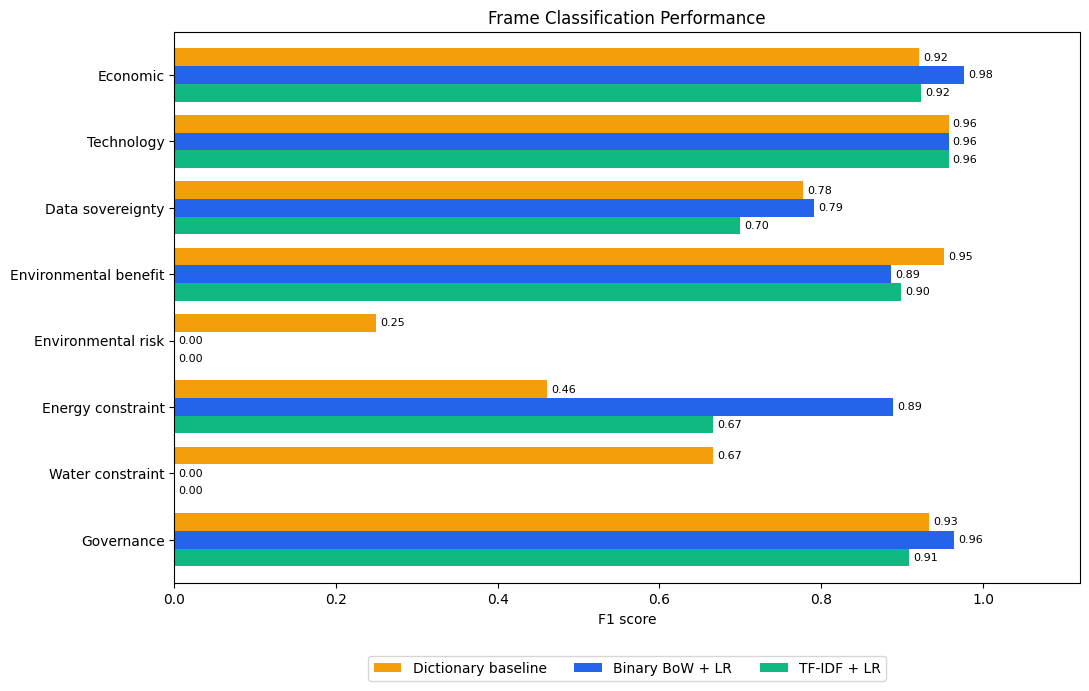

In [114]:
plot_data = (
    frame_results[
        frame_results["Model"] != "Majority baseline"
    ]
    .pivot(index="Frame", columns="Model", values="F1")
    .reindex([frame.removesuffix("_frame") for frame in frame_columns])
)

plot_data.index = [
    frame.replace("_", " ").capitalize()
    for frame in plot_data.index
]

plot_data = plot_data[
    ["Dictionary baseline", "Binary BoW + LR", "TF-IDF + LR"]
]

ax = plot_data.plot.barh(
    figsize=(11, 7),
    color=["#F59E0B", "#2563EB", "#10B981"],
    width=0.8
)

ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xlabel("F1 score")
ax.set_ylabel("")
ax.set_title("Frame Classification Performance")
ax.legend(title="", loc="upper center",
          bbox_to_anchor=(0.5, -0.12), ncol=3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=8)

plt.tight_layout()
plt.savefig("frame_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Error Analysis

In [115]:
predicted = predictions["Binary BoW + LR"]

for i, frame in enumerate(frame_columns):
    errors = model_df.loc[
        y[:, i] != predicted[:, i],
        ["article_id", "clean_text"]
    ].copy()

    errors["Human label"] = y[y[:, i] != predicted[:, i], i]
    errors["Prediction"] = predicted[y[:, i] != predicted[:, i], i]

    print(f"\n{frame}: {len(errors)} errors")
    display(errors)


economic_frame: 2 errors


,article_id,clean_text,Human label,Prediction
25,A032,өнгөрөгч сард манай улсад зохион байгуулагдсан...,0,1
37,A050,үндэсний дата төвийн стратегийн гол зорилтууды...,0,1



technology_frame: 4 errors


,article_id,clean_text,Human label,Prediction
9,A014,н.учрал: cop17 хурлын үеэр ногоон дата төв дээ...,0,1
12,A018,"газрын доройтол, цөлжилт, гангийн асуудлаар дэ...",0,1
13,A019,cop17 хурлын үеэр монгол улс ai ногоон дата тө...,0,1
42,A057,цөлжилттэй тэмцэх нүб-ийн конвенцын талуудын 1...,0,1



data_sovereignty_frame: 9 errors


...

,article_id,clean_text,Human label,Prediction
15,A021,монгол улсад ногоон дата төв байгуулах эдийн з...,1,0
23,A030,cop17-ын үеэр “монгол улсад ногоон дата төв ба...,1,0
37,A050,үндэсний дата төвийн стратегийн гол зорилтууды...,1,0
46,A062,засгийн газрын ээлжит хуралдаанаас гаргасан ши...,1,0



water_constraint_frame: 3 errors


,article_id,clean_text,Human label,Prediction
8,A013,улаанбаатар хотноо болж буй нүб-ын цөлжилттэй ...,1,0
16,A022,"хүйтэн уур амьсгал, эрчим хүч, газар нутаг, да...",1,0
48,A064,монголд ai data center хийх хэрэгтэй юу?\nб.ба...,1,0



governance_frame: 3 errors


,article_id,clean_text,Human label,Prediction
0,A002,"цөлжилт, газрын доройтол, гангийн асуудлаар дэ...",0,1
9,A014,н.учрал: cop17 хурлын үеэр ногоон дата төв дээ...,0,1
19,A025,"монгол улс хиймэл оюунд суурилсан, эрчим хүчни...",0,1


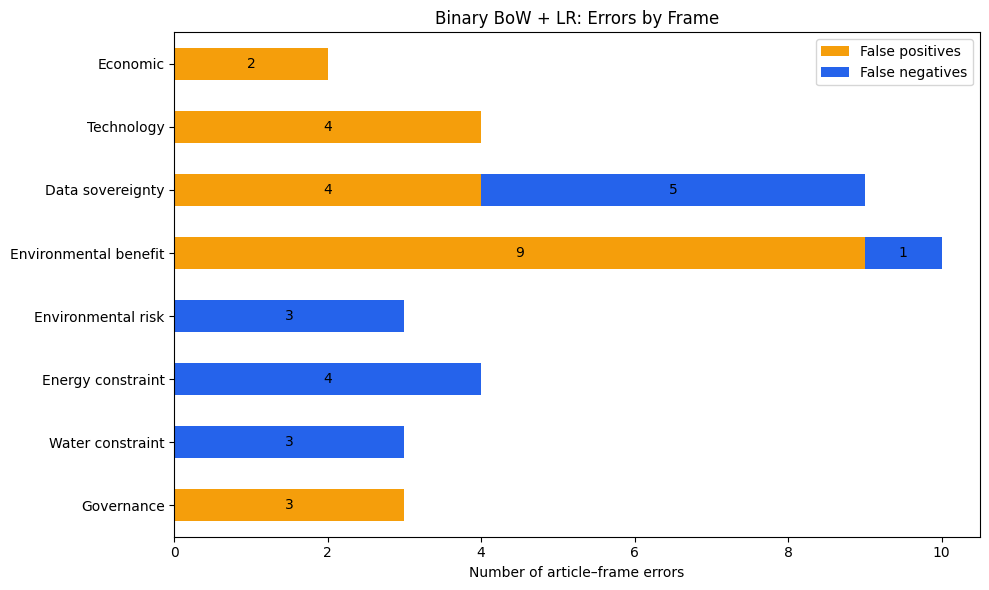

In [116]:
predicted = predictions["Binary BoW + LR"]

error_counts = pd.DataFrame({
    "False positives": ((y == 0) & (predicted == 1)).sum(axis=0),
    "False negatives": ((y == 1) & (predicted == 0)).sum(axis=0)
}, index=[
    frame.removesuffix("_frame").replace("_", " ").capitalize()
    for frame in frame_columns
])

ax = error_counts.plot.barh(
    stacked=True,
    figsize=(10, 6),
    color=["#F59E0B", "#2563EB"]
)

ax.invert_yaxis()
ax.set_title("Binary BoW + LR: Errors by Frame")
ax.set_xlabel("Number of article–frame errors")
ax.set_ylabel("")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(title="")

for container in ax.containers:
    labels = [str(int(v)) if v > 0 else "" for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type="center")

plt.tight_layout()
plt.show()

# Revised Model with Balanced Class Weights

In [117]:
from sklearn.base import clone
revised_model = {
    "Binary BoW + LR": Pipeline([
        ("vectorizer", CountVectorizer(
            binary=True,
            stop_words=stopwords,
            ngram_range=(1, 1),
            min_df=1
        )),
        ("classifier", OneVsRestClassifier(
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced")))
    ])
}

revised_prediction = {
    "Binary BoW + LR": np.zeros_like(y)
}

for train_idx, test_idx in splits:
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y[train_idx]

    for name, model in revised_model.items():
        fitted_model = clone(model)
        fitted_model.fit(X_train, y_train)

        revised_prediction[name][test_idx] = fitted_model.predict(X_test)

original = predictions["Binary BoW + LR"]
balanced = revised_prediction["Binary BoW + LR"]

def evaluate_frames(predicted):
    precision, recall, f1, support = precision_recall_fscore_support(
        y, predicted, average=None, zero_division=0
    )

    return pd.DataFrame({
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Errors": (y != predicted).sum(axis=0),
        "False positives": ((y == 0) & (predicted == 1)).sum(axis=0),
        "False negatives": ((y == 1) & (predicted == 0)).sum(axis=0)
    }, index=[frame.removesuffix("_frame") for frame in frame_columns])

original_scores = evaluate_frames(original)
balanced_scores = evaluate_frames(balanced)

score_comparison = pd.concat(
    {"Original": original_scores, "Balanced": balanced_scores},
    axis=1
)

score_comparison[("Change", "F1")] = (
    balanced_scores["F1"] - original_scores["F1"]
)
score_comparison[("Change", "Errors")] = (
    balanced_scores["Errors"] - original_scores["Errors"]
)

display(score_comparison.round(3))

Original                                       \
                      Precision Recall     F1 Errors False positives   
economic                  0.955  1.000  0.977      2               2   
technology                0.918  1.000  0.957      4               4   
data_sovereignty          0.810  0.773  0.791      9               4   
environmental_benefit     0.812  0.975  0.886     10               9   
environmental_risk        0.000  0.000  0.000      3               0   
energy_constraint         1.000  0.800  0.889      4               0   
water_constraint          0.000  0.000  0.000      3               0   
governance                0.930  1.000  0.964      3               3   

                                       Balanced                       \
                      False negatives Precision Recall     F1 Errors   
economic                            0     0.953  0.976  0.965      3   
technology                          0     0.917  0.978  0.946      5   
data_sovereignty                    5     0.810  0.773  0.791      9   
environmental_benefit               1     0.830  0.975  0.897      9   
environmental_risk                  3     0.000  0.000  0.000      3   
energy_constraint                   4     1.000  0.850  0.919      3   
water_constraint                    3     0.000  0.000  0.000      3   
governance                          0     0.952  1.000  0.976      2   

                                                      Change         
                      False positives False negatives     F1 Errors  
economic                            2               1 -0.012      1  
technology                          4               1 -0.011      1  
data_sovereignty                    4               5  0.000      0  
environmental_benefit               8               1  0.010     -1  
environmental_risk                  0               3  0.000      0  
energy_constraint                   0               3  0.030     -1  
water_constraint                    0               3  0.000      0  
governance                          2               0  0.012     -1

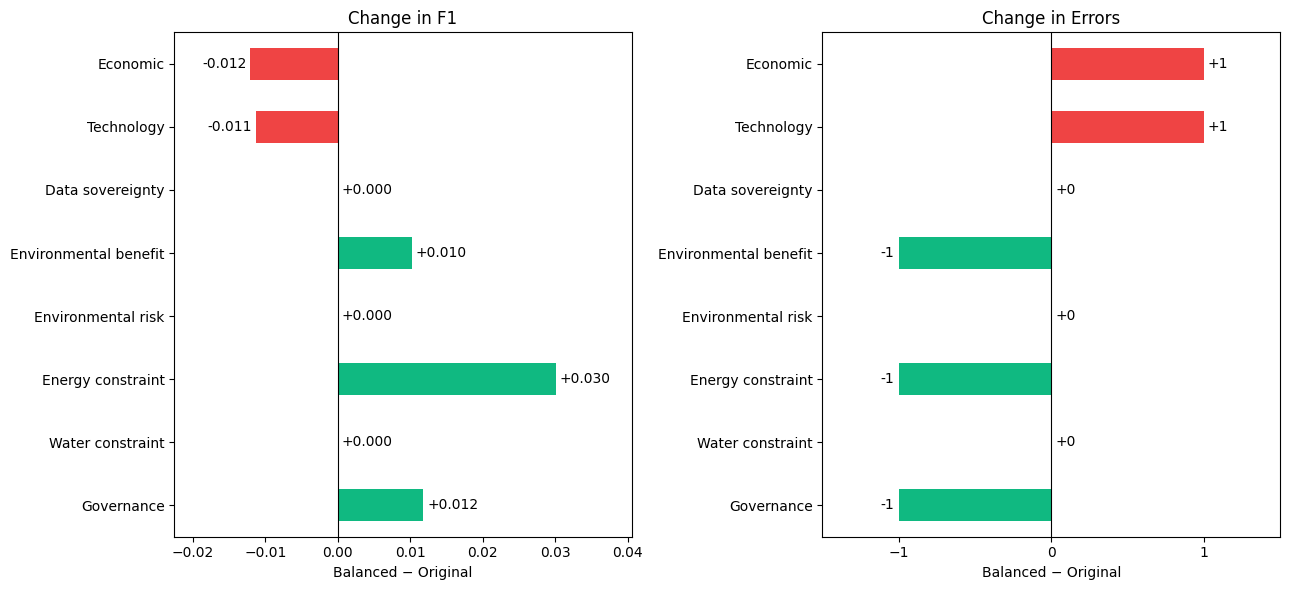

In [118]:
changes = score_comparison["Change"].copy()
changes.index = [
    frame.replace("_", " ").capitalize()
    for frame in changes.index
]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, metric in zip(axes, ["F1", "Errors"]):
    values = changes[metric]

    improved = values > 0 if metric == "F1" else values < 0
    colors = [
        "#9CA3AF" if value == 0 else
        "#10B981" if good else "#EF4444"
        for value, good in zip(values, improved)
    ]

    values.plot.barh(ax=ax, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()
    ax.set_ylabel("")
    ax.set_title(f"Change in {metric}")
    ax.set_xlabel("Balanced − Original")
    ax.margins(x=0.25)

    ax.bar_label(
        ax.containers[0],
        fmt="%+.3f" if metric == "F1" else "%+.0f",
        padding=3
    )

axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()